In [83]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs(
    r"F:\HolidayWeather\figures",
    exist_ok=True
)

In [65]:
max_ds = xr.open_dataset(
    r"F:\HolidayWeather\data\raw\april_max_temp_1991_2025.nc"
)

min_ds = xr.open_dataset(
    r"F:\HolidayWeather\data\raw\april_min_temp_1991_2025.nc"
)

precip_ds = xr.open_dataset(
    r"F:\HolidayWeather\data\raw\april_precip_1991_2025.nc"
)

In [68]:
max_ds["t2m_c"] = max_ds["t2m"] - 273.15
min_ds["t2m_c"] = min_ds["t2m"] - 273.15

precip_ds["tp_mm"] = precip_ds["tp"] * 1000

In [69]:
expanded_locations = {

    # Portugal
    "Faro": (37.02, -7.93),
    "Albufeira": (37.09, -8.25),
    "Lagos": (37.10, -8.67),

    # South France
    "Aix-en-Provence": (43.53, 5.45),
    "Cassis": (43.21, 5.54),
    "Saint-Tropez": (43.27, 6.64),
    "Nice": (43.70, 7.27),
    "Montpellier": (43.61, 3.88),

    # Spain
    "Sitges": (41.24, 1.81),
    "Tarragona": (41.12, 1.24),
    "Costa_Brava": (41.98, 3.20),

    # Croatia
    "Split": (43.51, 16.44),
    "Makarska": (43.30, 17.02),
    "Hvar": (43.17, 16.44),
    "Dubrovnik": (42.65, 18.09),

    # Bosnia
    "Mostar": (43.34, 17.81),
    "Trebinje": (42.71, 18.34),

    # Romania
    "Brasov": (45.66, 25.61),
    "Sibiu": (45.79, 24.15),
    "Constanta": (44.17, 28.63),
}

In [ ]:


results = []

for name, (lat, lon) in expanded_locations.items():

    temp = max_ds["t2m_c"].sel(
        latitude=lat,
        longitude=lon,
        method="nearest"
    )

    results.append({
        "Location": name,
        "Mean_Max": float(temp.mean()),
        "Median_Max": float(temp.median()),
        "P(Max>18C)": float((temp > 18).mean() * 100),
        "P(Max>20C)": float((temp > 20).mean() * 100),
        "P(Max>22C)": float((temp > 22).mean() * 100),
    })

max_df = pd.DataFrame(results)

max_df.sort_values(
    "Median_Max",
    ascending=False
).round(1)

,Location,Mean_Max,Median_Max,P(Max>18C),P(Max>20C),P(Max>22C)
3,Aix-en-Provence,17.1,17.2,40.7,16.8,3.9
1,Albufeira,17.1,17.1,28.6,5.0,0.0
0,Faro,17.0,17.0,27.1,4.6,0.0
2,Lagos,16.6,16.7,20.4,1.8,0.0
9,Tarragona,16.6,16.5,26.8,5.4,0.7
8,Sitges,16.1,16.0,20.7,2.5,0.4
15,Mostar,15.4,15.3,26.4,12.9,6.4
7,Montpellier,15.5,15.2,10.7,1.4,0.7
4,Cassis,15.2,15.2,8.2,1.1,0.4
14,Dubrovnik,14.9,15.1,13.9,4.3,0.7


In [ ]:
max_ds = xr.open_dataset(
    r"F:\HolidayWeather\data\raw\april_max_temp_1991_2025.nc"
)

min_ds = xr.open_dataset(
    r"F:\HolidayWeather\data\raw\april_min_temp_1991_2025.nc"
)

precip_ds = xr.open_dataset(
    r"F:\HolidayWeather\data\raw\april_precip_1991_2025.nc"
)

In [ ]:
max_results = []

for name, (lat, lon) in expanded_locations.items():

    temp = max_ds["t2m_c"].sel(
        latitude=lat,
        longitude=lon,
        method="nearest"
    )

    max_results.append({
        "Location": name,
        "Mean_Max": float(temp.mean()),
        "Median_Max": float(temp.median()),
        "P(Max>18C)": float((temp > 18).mean() * 100),
        "P(Max>20C)": float((temp > 20).mean() * 100),
        "P(Max>22C)": float((temp > 22).mean() * 100),
    })

max_df = pd.DataFrame(max_results)

max_df.sort_values(
    "Median_Max",
    ascending=False
).round(1)

,Location,Mean_Max,Median_Max,P(Max>18C),P(Max>20C),P(Max>22C)
3,Aix-en-Provence,17.1,17.2,40.7,16.8,3.9
1,Albufeira,17.1,17.1,28.6,5.0,0.0
0,Faro,17.0,17.0,27.1,4.6,0.0
2,Lagos,16.6,16.7,20.4,1.8,0.0
9,Tarragona,16.6,16.5,26.8,5.4,0.7
8,Sitges,16.1,16.0,20.7,2.5,0.4
15,Mostar,15.4,15.3,26.4,12.9,6.4
7,Montpellier,15.5,15.2,10.7,1.4,0.7
4,Cassis,15.2,15.2,8.2,1.1,0.4
14,Dubrovnik,14.9,15.1,13.9,4.3,0.7


In [ ]:
min_results = []

for name, (lat, lon) in expanded_locations.items():

    temp = min_ds["t2m_c"].sel(
        latitude=lat,
        longitude=lon,
        method="nearest"
    )

    min_results.append({
        "Location": name,
        "Mean_Min": float(temp.mean()),
        "Median_Min": float(temp.median()),
        "P(Min>10C)": float((temp > 10).mean() * 100),
        "P(Min>12C)": float((temp > 12).mean() * 100),
        "P(Min>15C)": float((temp > 15).mean() * 100),
    })

min_df = pd.DataFrame(min_results)

min_df.sort_values(
    "Median_Min",
    ascending=False
).round(1)

,Location,Mean_Min,Median_Min,P(Min>10C),P(Min>12C),P(Min>15C)
2,Lagos,13.8,13.9,100.0,85.7,22.5
1,Albufeira,13.6,13.7,98.9,80.4,25.0
0,Faro,13.6,13.6,98.9,79.6,25.7
13,Hvar,11.8,12.2,83.9,57.5,2.9
10,Costa_Brava,11.7,11.9,88.9,45.7,0.7
5,Saint-Tropez,11.6,11.6,84.3,39.3,0.0
9,Tarragona,11.3,11.4,78.9,35.0,1.1
7,Montpellier,10.4,10.5,59.6,21.1,0.4
8,Sitges,10.0,9.9,48.9,12.1,0.7
4,Cassis,9.9,9.9,47.1,13.9,0.0


In [73]:
rain_results = []

for name, (lat, lon) in expanded_locations.items():

    rain = precip_ds["tp_mm"].sel(
        latitude=lat,
        longitude=lon,
        method="nearest"
    )

    rain_results.append({
        "Location": name,
        "Median_Rain_mm": float(rain.median()),
        "Mean_Rain_mm": float(rain.mean()),
        "Wet_Day_%": float((rain > 1).mean() * 100),
        "Heavy_Rain_%": float((rain > 5).mean() * 100),
    })

rain_df = pd.DataFrame(rain_results)

rain_df.sort_values("Wet_Day_%").round(1)

,Location,Median_Rain_mm,Mean_Rain_mm,Wet_Day_%,Heavy_Rain_%
1,Albufeira,0.0,1.3,18.9,7.9
0,Faro,0.0,1.5,19.3,8.2
9,Tarragona,0.0,1.4,19.3,8.2
5,Saint-Tropez,0.0,1.7,20.4,7.1
10,Costa_Brava,0.0,1.4,21.1,7.5
2,Lagos,0.0,1.3,22.9,8.2
4,Cassis,0.0,1.3,22.9,7.9
7,Montpellier,0.0,1.3,23.9,7.9
19,Constanta,0.1,1.3,24.3,8.6
8,Sitges,0.1,1.5,25.0,8.9


In [21]:
final_df = (
    max_df
    .merge(min_df, on="Location")
    .merge(rain_df, on="Location")
)

final_df.round(1)

,Location,Mean_Max,Median_Max,P(Max>18C),P(Max>20C),P(Max>22C),Mean_Min,Median_Min,P(Min>10C),P(Min>12C),P(Min>15C),Median_Rain_mm,Mean_Rain_mm,Wet_Day_%,Heavy_Rain_%
0,Faro,17.0,17.0,27.1,4.6,0.0,13.6,13.6,98.9,79.6,25.7,0.0,1.5,19.3,8.2
1,Albufeira,17.1,17.1,28.6,5.0,0.0,13.6,13.7,98.9,80.4,25.0,0.0,1.3,18.9,7.9
2,Lagos,16.6,16.7,20.4,1.8,0.0,13.8,13.9,100.0,85.7,22.5,0.0,1.3,22.9,8.2
3,Aix-en-Provence,17.1,17.2,40.7,16.8,3.9,7.0,6.9,11.8,3.2,0.0,0.0,1.6,28.9,10.0
4,Cassis,15.2,15.2,8.2,1.1,0.4,9.9,9.9,47.1,13.9,0.0,0.0,1.3,22.9,7.9
5,Saint-Tropez,15.0,15.0,5.0,0.4,0.0,11.6,11.6,84.3,39.3,0.0,0.0,1.7,20.4,7.1
6,Nice,14.6,14.7,7.9,1.4,0.0,7.5,7.6,10.7,1.4,0.0,0.4,2.3,33.6,14.3
7,Montpellier,15.5,15.2,10.7,1.4,0.7,10.4,10.5,59.6,21.1,0.4,0.0,1.3,23.9,7.9
8,Sitges,16.1,16.0,20.7,2.5,0.4,10.0,9.9,48.9,12.1,0.7,0.1,1.5,25.0,8.9
9,Tarragona,16.6,16.5,26.8,5.4,0.7,11.3,11.4,78.9,35.0,1.1,0.0,1.4,19.3,8.2


In [74]:
report_df = final_df[
    [
        "Location",
        "Median_Max",
        "Median_Min",
        "P(Max>18C)",
        "P(Max>20C)",
        "Wet_Day_%"
    ]
].round(1)

report_df

,Location,Median_Max,Median_Min,P(Max>18C),P(Max>20C),Wet_Day_%
0,Faro,17.0,13.6,27.1,4.6,19.3
1,Albufeira,17.1,13.7,28.6,5.0,18.9
2,Lagos,16.7,13.9,20.4,1.8,22.9
3,Aix-en-Provence,17.2,6.9,40.7,16.8,28.9
4,Cassis,15.2,9.9,8.2,1.1,22.9
5,Saint-Tropez,15.0,11.6,5.0,0.4,20.4
6,Nice,14.7,7.6,7.9,1.4,33.6
7,Montpellier,15.2,10.5,10.7,1.4,23.9
8,Sitges,16.0,9.9,20.7,2.5,25.0
9,Tarragona,16.5,11.4,26.8,5.4,19.3


In [76]:
final_report = (
    max_df.merge(min_df, on="Location")
          .merge(rain_df, on="Location")
)

In [77]:
report_df = final_report[
    [
        "Location",
        "Median_Max",
        "Median_Min",
        "P(Max>18C)",
        "P(Max>20C)",
        "Wet_Day_%"
    ]
].round(1)

report_df.sort_values(
    "Median_Max",
    ascending=False
)

,Location,Median_Max,Median_Min,P(Max>18C),P(Max>20C),Wet_Day_%
3,Aix-en-Provence,17.2,6.9,40.7,16.8,28.9
1,Albufeira,17.1,13.7,28.6,5.0,18.9
0,Faro,17.0,13.6,27.1,4.6,19.3
2,Lagos,16.7,13.9,20.4,1.8,22.9
9,Tarragona,16.5,11.4,26.8,5.4,19.3
8,Sitges,16.0,9.9,20.7,2.5,25.0
15,Mostar,15.3,5.1,26.4,12.9,43.6
4,Cassis,15.2,9.9,8.2,1.1,22.9
7,Montpellier,15.2,10.5,10.7,1.4,23.9
14,Dubrovnik,15.1,8.5,13.9,4.3,43.2


In [78]:
report_df["Country"] = report_df["Location"].map(
    location_country
)

In [79]:
summary_df = report_df[
    [
        "Country",
        "Location",
        "Median_Max",
        "Median_Min",
        "P(Max>18C)",
        "Wet_Day_%"
    ]
].sort_values(
    ["Country","Median_Max"],
    ascending=[True,False]
)

summary_df

,Country,Location,Median_Max,Median_Min,P(Max>18C),Wet_Day_%
15,Bosnia & Herzegovina,Mostar,15.3,5.1,26.4,43.6
16,Bosnia & Herzegovina,Trebinje,13.8,7.2,6.8,46.1
14,Croatia,Dubrovnik,15.1,8.5,13.9,43.2
12,Croatia,Makarska,14.4,9.3,6.8,38.9
13,Croatia,Hvar,14.1,12.2,0.4,30.7
11,Croatia,Split,13.9,9.7,3.9,35.0
3,France,Aix-en-Provence,17.2,6.9,40.7,28.9
4,France,Cassis,15.2,9.9,8.2,22.9
7,France,Montpellier,15.2,10.5,10.7,23.9
5,France,Saint-Tropez,15.0,11.6,5.0,20.4


In [80]:
x_mid = 30
y_mid = 15

print(x_mid, y_mid)

30 15


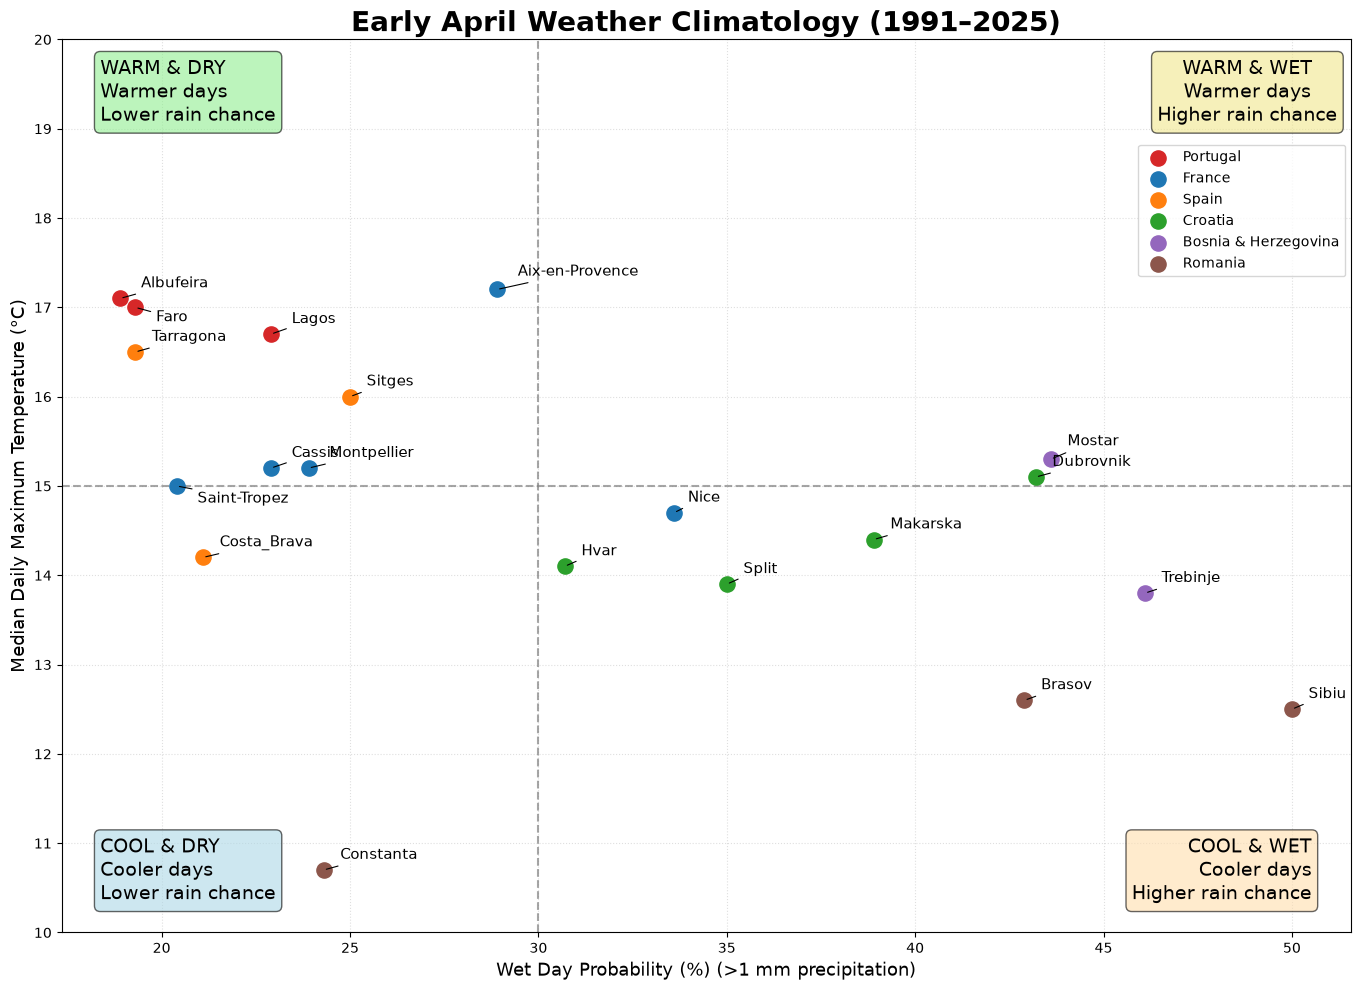

In [ ]:
fig, ax = plt.subplots(figsize=(14, 10))

# ----------------------------
# Country colours
# ----------------------------

country_colors = {
    "Portugal": "tab:red",
    "France": "tab:blue",
    "Spain": "tab:orange",
    "Croatia": "tab:green",
    "Bosnia & Herzegovina": "tab:purple",
    "Romania": "tab:brown"
}

# ----------------------------
# Scatter points
# ----------------------------

for country in report_df["Country"].unique():

    subset = report_df[
        report_df["Country"] == country
    ]

    ax.scatter(
        subset["Wet_Day_%"],
        subset["Median_Max"],
        color=country_colors[country],
        s=120,
        label=country,
        zorder=3
    )

    ax.set_ylim(10, 20)
    ax.set_yticks(range(10, 21))


# ----------------------------
# Quadrant lines
# ----------------------------

ax.axvline(
    x_mid,
    color="grey",
    linestyle="--",
    alpha=0.7
)

ax.axhline(
    y_mid,
    color="grey",
    linestyle="--",
    alpha=0.7
)

# ----------------------------
# Custom label positions
# ----------------------------

label_offsets = {

    "Faro": (15, -10),
    "Albufeira": (15, 8),
    "Lagos": (15, 8),

    "Tarragona": (12, 8),
    "Sitges": (12, 8),
    "Costa_Brava": (12, 8),

    "Aix-en-Provence": (15, 10),
    "Saint-Tropez": (15, -12),
    "Cassis": (15, 8),
    "Montpellier": (15, 8),
    "Nice": (10, 8),

    "Dubrovnik": (12, 8),
    "Split": (12, 8),
    "Hvar": (12, 8),
    "Makarska": (12, 8),

    "Mostar": (12, 10),
    "Trebinje": (12, 8),

    "Brasov": (12, 8),
    "Sibiu": (12, 8),
    "Constanta": (12, 8),
}

# ----------------------------
# Labels
# ----------------------------

for _, row in report_df.iterrows():

    dx, dy = label_offsets.get(
        row["Location"],
        (12, 8)
    )

    ax.annotate(
        row["Location"],
        xy=(row["Wet_Day_%"], row["Median_Max"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=11,
        arrowprops=dict(
            arrowstyle="-",
            lw=0.8,
            color="black"
        )
    )

# ----------------------------
# Quadrant boxes
# ----------------------------

ax.text(
    0.03,
    0.98,
    "WARM & DRY\nWarmer days\nLower rain chance",
    transform=ax.transAxes,
    va="top",
    fontsize=14,
    bbox=dict(
        boxstyle="round",
        facecolor="lightgreen",
        alpha=0.6
    )
)

ax.text(
    0.92,
    0.98,
    "WARM & WET\nWarmer days\nHigher rain chance",
    transform=ax.transAxes,
    va="top",
    ha="center",
    fontsize=14,
    bbox=dict(
        boxstyle="round",
        facecolor="khaki",
        alpha=0.6
    )
)

ax.text(
    0.03,
    0.03,
    "COOL & DRY\nCooler days\nLower rain chance",
    transform=ax.transAxes,
    va="bottom",
    fontsize=14,
    bbox=dict(
        boxstyle="round",
        facecolor="lightblue",
        alpha=0.6
    )
)

ax.text(
    0.97,
    0.03,
    "COOL & WET\nCooler days\nHigher rain chance",
    transform=ax.transAxes,
    va="bottom",
    ha="right",
    fontsize=14,
    bbox=dict(
        boxstyle="round",
        facecolor="navajowhite",
        alpha=0.6
    )
)

# ----------------------------
# Legend outside plot
# ----------------------------

ax.legend(
    bbox_to_anchor=(0.83, 0.89),
    loc="upper left",
    frameon=True
)

# ----------------------------
# Formatting
# ----------------------------

ax.set_title(
    "Early April Weather Climatology (1991–2025)",
    fontsize=20,
    weight="bold"
)

ax.set_xlabel(
    "Wet Day Probability (%) (>1 mm precipitation)",
    fontsize=13
)

ax.set_ylabel(
    "Median Daily Maximum Temperature (°C)",
    fontsize=13
)

ax.grid(
    True,
    linestyle=":",
    alpha=0.4
)

plt.tight_layout()
plt.savefig(
    r"F:\HolidayWeather\figures\weather_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

In [82]:
report_df.to_csv(
    r"F:\HolidayWeather\data\processed\holiday_weather_report.csv",
    index=False
)

In [85]:
summary_df = report_df[
    [
        "Country",
        "Location",
        "Median_Max",
        "Median_Min",
        "P(Max>18C)",
        "P(Max>20C)",
        "Wet_Day_%",
    ]
].round(1)

In [86]:
summary_df.sort_values(
    ["Country", "Median_Max"],
    ascending=[True, False]
)

,Country,Location,Median_Max,Median_Min,P(Max>18C),P(Max>20C),Wet_Day_%
15,Bosnia & Herzegovina,Mostar,15.3,5.1,26.4,12.9,43.6
16,Bosnia & Herzegovina,Trebinje,13.8,7.2,6.8,2.5,46.1
14,Croatia,Dubrovnik,15.1,8.5,13.9,4.3,43.2
12,Croatia,Makarska,14.4,9.3,6.8,1.1,38.9
13,Croatia,Hvar,14.1,12.2,0.4,0.0,30.7
11,Croatia,Split,13.9,9.7,3.9,0.4,35.0
3,France,Aix-en-Provence,17.2,6.9,40.7,16.8,28.9
4,France,Cassis,15.2,9.9,8.2,1.1,22.9
7,France,Montpellier,15.2,10.5,10.7,1.4,23.9
5,France,Saint-Tropez,15.0,11.6,5.0,0.4,20.4


In [ ]:
country_summaries = []

for country in sorted(report_df["Country"].unique()):

    subset = report_df[report_df["Country"] == country]

    max_min = subset["Median_Max"].min()
    max_max = subset["Median_Max"].max()

    min_min = subset["Median_Min"].min()
    min_max = subset["Median_Min"].max()

    warm_min = subset["P(Max>20C)"].min()
    warm_max = subset["P(Max>20C)"].max()

    wet_min = subset["Wet_Day_%"].min()
    wet_max = subset["Wet_Day_%"].max()

    summary = f"""
## {country}
### 3–10 April (1991–2025)

**Typical afternoon maximum:**  
{max_min:.0f}–{max_max:.0f}°C

**Typical overnight minimum:**  
{min_min:.0f}–{min_max:.0f}°C

**Chance of reaching 20°C:**  
{warm_min:.0f}–{warm_max:.0f}%

**Chance of a wet day (>1 mm):**  
{wet_min:.0f}–{wet_max:.0f}%

---
"""

    country_summaries.append(summary)

report_text = "\n".join(country_summaries)


In [ ]:
with open(
    r"F:\HolidayWeather\country_weather_summary.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(report_text)

print("Markdown report saved")

In [90]:
country_descriptions = {
    "Portugal":
        "The Algarve offers the most reliable weather with mild days, warm nights and relatively low rainfall.",

    "France":
        "Southern France has the greatest potential for warm spring afternoons but cooler mornings and evenings.",

    "Spain":
        "Catalonia offers balanced conditions with moderate temperatures and relatively low rainfall.",

    "Croatia":
        "The Croatian coast is cooler and wetter than many people expect in early April.",

    "Bosnia & Herzegovina":
        "Bosnia shows the greatest variability with both warm days and cool nights possible.",

    "Romania":
        "Romania remains distinctly spring-like with cool nights and highly variable weather."
}

In [91]:
summary += f"""
**Summary:**  
{country_descriptions[country]}

---
"""

In [93]:
country_summaries = []

for country in sorted(report_df["Country"].unique()):

    subset = report_df[report_df["Country"] == country]

    max_min = subset["Median_Max"].min()
    max_max = subset["Median_Max"].max()

    min_min = subset["Median_Min"].min()
    min_max = subset["Median_Min"].max()

    warm_min = subset["P(Max>20C)"].min()
    warm_max = subset["P(Max>20C)"].max()

    wet_min = subset["Wet_Day_%"].min()
    wet_max = subset["Wet_Day_%"].max()

    description = country_descriptions.get(
        country,
        "No summary available."
    )

    summary = f"""
## {country}
### 3–10 April (1991–2025)

**Typical afternoon maximum:**  
{max_min:.0f}–{max_max:.0f}°C

**Typical overnight minimum:**  
{min_min:.0f}–{min_max:.0f}°C

**Chance of reaching 20°C:**  
{warm_min:.0f}–{warm_max:.0f}%

**Chance of a wet day (>1 mm):**  
{wet_min:.0f}–{wet_max:.0f}%

**Summary:**  
{description}

---
"""

    country_summaries.append(summary)

report_text = "\n".join(country_summaries)

In [ ]:
with open(
    r"F:\HolidayWeather\country_weather_summary_2.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(report_text)

print("Report saved")

In [ ]:
for country, description in country_descriptions.items():
    print(f"\n**Summary:**\n{description}\n")